In [28]:
import os, shutil, time, warnings
import numpy as np
import torch
import torch.nn as nn
import torch.optim as optim
from torchvision import datasets, transforms, models
from torch.utils.data import DataLoader, random_split
from sklearn.metrics import f1_score, confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns
warnings.filterwarnings("ignore")

# Confirm CUDA — ResNet/DenseNet on CalTech-101 is impractical on CPU
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Using device: {device}")
if device.type == "cuda":
    print(f"GPU : {torch.cuda.get_device_name(0)}")
    print(f"VRAM: {torch.cuda.get_device_properties(0).total_memory / 1e9:.1f} GB")

Using device: cuda
GPU : NVIDIA RTX 4000 Ada Generation
VRAM: 21.0 GB


In [29]:
class Config:
    BASE_PATH    = "/home/btech02_06/Downloads/TL_DATA/101_ObjectCategories"
    BATCH_SIZE   = 32       # fits GPU VRAM; 64 risks OOM on 4000 Ada with DenseNet
    EPOCHS       = 50       # max; early stopping cuts this short
    PATIENCE     = 5        # stop if val_loss doesn't improve for 5 consecutive epochs
    WEIGHT_DECAY = 1e-4     # L2 regularization — critical for small dataset like CalTech-101
    MOMENTUM     = 0.9      # standard SGD momentum from ImageNet training literature
    SEED         = 42
    DEVICE       = device

torch.manual_seed(Config.SEED)
if device.type == "cuda":
    torch.cuda.manual_seed(Config.SEED)

print("Config loaded.")

Config loaded.


In [30]:
# Fix nested folder issue CalTech-101 download sometimes creates
nested = os.path.join(Config.BASE_PATH, "101_ObjectCategories")
if os.path.exists(nested):
    for item in os.listdir(nested):
        shutil.move(os.path.join(nested, item), Config.BASE_PATH)
    shutil.rmtree(nested)

# ImageFolder: each subfolder = one class, auto-assigns integer labels
dataset     = datasets.ImageFolder(root=Config.BASE_PATH)
num_classes = len(dataset.classes)  # 102: 101 categories + BACKGROUND_Google

print(f"Classes : {num_classes}")
print(f"Images  : {len(dataset)}")

Classes : 102
Images  : 9144


In [31]:
# Resize→256 then CenterCrop→224 matches how ImageNet pretrained models expect input
# Normalization constants = ImageNet per-channel mean and std (required for pretrained weights)
transform_train = transforms.Compose([
    transforms.Resize(256),
    transforms.CenterCrop(224),
    transforms.RandomHorizontalFlip(),           # light augmentation — reduces overfitting
    transforms.ColorJitter(0.2, 0.2, 0.2),      # small color perturbation for robustness
    transforms.ToTensor(),
    transforms.Normalize([0.485, 0.456, 0.406],
                         [0.229, 0.224, 0.225])  # ImageNet channel-wise mean/std
])

transform_val_test = transforms.Compose([
    transforms.Resize(256),
    transforms.CenterCrop(224),
    transforms.ToTensor(),
    transforms.Normalize([0.485, 0.456, 0.406],
                         [0.229, 0.224, 0.225])  # no augmentation at val/test — deterministic
])

print("Transforms defined.")

Transforms defined.


In [32]:
total_size = len(dataset)
train_size = int(0.7 * total_size)
val_size   = int(0.1 * total_size)
test_size  = total_size - train_size - val_size  # remainder → test, avoids rounding loss

# manual_seed(42) guarantees same split every run — reproducibility
train_ds_raw, val_ds_raw, test_ds_raw = random_split(
    dataset, [train_size, val_size, test_size],
    generator=torch.Generator().manual_seed(Config.SEED)
)

print(f"Train : {train_size}")
print(f"Val   : {val_size}")
print(f"Test  : {test_size}")

Train : 6400
Val   : 914
Test  : 1830


In [33]:
class TransformDataset(torch.utils.data.Dataset):
    """Wraps a Subset and applies a transform — split FIRST, transform AFTER
       prevents augmentation leaking into val/test indices."""
    def __init__(self, subset, transform=None):
        self.subset    = subset
        self.transform = transform

    def __len__(self):
        return len(self.subset)

    def __getitem__(self, idx):
        img, label = self.subset[idx]
        if self.transform:
            img = self.transform(img)
        return img, label


train_ds = TransformDataset(train_ds_raw, transform_train)
val_ds   = TransformDataset(val_ds_raw,   transform_val_test)
test_ds  = TransformDataset(test_ds_raw,  transform_val_test)

# pin_memory=True: keeps tensors in page-locked memory → faster CPU→GPU transfer
train_loader = DataLoader(train_ds, batch_size=Config.BATCH_SIZE,
                          shuffle=True,  num_workers=2, pin_memory=True)
val_loader   = DataLoader(val_ds,   batch_size=Config.BATCH_SIZE,
                          shuffle=False, num_workers=2, pin_memory=True)
test_loader  = DataLoader(test_ds,  batch_size=Config.BATCH_SIZE,
                          shuffle=False, num_workers=2, pin_memory=True)

# Sanity check
imgs, lbls = next(iter(train_loader))
print(f"Train batches : {len(train_loader)}")
print(f"Val   batches : {len(val_loader)}")
print(f"Test  batches : {len(test_loader)}")
print(f"Batch shape   : {imgs.shape}")
print(f"Classes       : {num_classes}")
print(f"Label range   : {lbls.min().item()} – {lbls.max().item()}")

Train batches : 200
Val   batches : 29
Test  batches : 58
Batch shape   : torch.Size([32, 3, 224, 224])
Classes       : 102
Label range   : 0 – 95


In [34]:
def get_model(name, num_classes):
    """Load ImageNet-pretrained backbone; replace classifier head for CalTech-101."""
    if name == "resnet50":
        # ResNet: H(x) = F(x) + x — additive skip prevents vanishing gradient in deep nets
        model = models.resnet50(weights=models.ResNet50_Weights.IMAGENET1K_V1)
        model.fc = nn.Linear(model.fc.in_features, num_classes)        # 2048 → 102

    elif name == "densenet121":
        # DenseNet: x_l = H([x_0,...,x_{l-1}]) — concatenation forces explicit feature reuse
        model = models.densenet121(weights=models.DenseNet121_Weights.IMAGENET1K_V1)
        model.classifier = nn.Linear(model.classifier.in_features, num_classes)  # 1024 → 102

    return model


def freeze_all(model):
    """Freeze entire backbone — gradients won't flow; only unfrozen layers update."""
    for p in model.parameters():
        p.requires_grad = False


def count_params(model):
    """Return (total, trainable) param counts for complexity reporting."""
    total     = sum(p.numel() for p in model.parameters())
    trainable = sum(p.numel() for p in model.parameters() if p.requires_grad)
    return total, trainable


print("Model utilities defined.")

Model utilities defined.


In [35]:
# ── CASE 1: ResNet-50 — Unfreeze top 2 groups: fc + layer4 ────────────────
# layer4 = 3 Bottleneck blocks, highest-level semantic features (shapes/objects)
# Freezing layer1–3 preserves low-level ImageNet features (edges, textures)
def unfreeze_resnet_case1(model):
    for p in model.fc.parameters():      # task-specific classification head
        p.requires_grad = True
    for p in model.layer4.parameters():  # last residual block group — most task-relevant
        p.requires_grad = True


# ── CASE 2: DenseNet-121 — Unfreeze top 3 groups: classifier + denseblock4 + transition3 ─
# denseblock4: densely connected final block — receives concatenated features from all prior layers
# transition3: conv+pool bridge feeding into denseblock4 — must adapt with block4
def unfreeze_densenet_case2(model):
    for p in model.classifier.parameters():              # head: 1024 → 102
        p.requires_grad = True
    for p in model.features.denseblock4.parameters():   # dense connectivity — highest-level
        p.requires_grad = True
    for p in model.features.transition3.parameters():   # spatial bridge before denseblock4
        p.requires_grad = True


print("Unfreeze functions defined.")

Unfreeze functions defined.


In [36]:
def train_epoch(model, loader, optimizer, criterion):
    """One full pass over training set. Returns average loss."""
    model.train()                          # enables dropout/batchnorm training mode
    running_loss = 0.0
    for imgs, labels in loader:
        imgs, labels = imgs.to(Config.DEVICE), labels.to(Config.DEVICE)
        optimizer.zero_grad()              # clear stale gradients from previous step
        loss = criterion(model(imgs), labels)
        loss.backward()                   # backprop only through requires_grad=True params
        optimizer.step()
        running_loss += loss.item()
    return running_loss / len(loader)


def validate_epoch(model, loader, criterion):
    """Evaluate on val/test set. Returns (avg_loss, top1_accuracy%)."""
    model.eval()                           # disables dropout; uses running BN stats
    running_loss, correct, total = 0.0, 0, 0
    with torch.no_grad():                  # no gradient tape — saves memory at eval
        for imgs, labels in loader:
            imgs, labels = imgs.to(Config.DEVICE), labels.to(Config.DEVICE)
            out = model(imgs)
            running_loss += criterion(out, labels).item()
            correct += (out.argmax(1) == labels).sum().item()  # top-1 prediction
            total   += labels.size(0)
    return running_loss / len(loader), 100 * correct / total


print("Epoch functions defined.")

Epoch functions defined.


In [37]:
def run_hp_search(model_name, unfreeze_fn, search_space, search_epochs=5):
    """
    Grid search over optimizer × lr × scheduler.
    5 epochs per combo is enough to rank configs — full training done separately.
    Fresh model per combo prevents state contamination between runs.
    """
    results = []
    n = (len(search_space["optimizer"]) *
         len(search_space["lr"]) *
         len(search_space["scheduler"]))
    print(f"\n{'='*65}")
    print(f"HP SEARCH — {model_name.upper()} | {n} combos × {search_epochs} epochs each")
    print(f"{'='*65}")

    for opt_name in search_space["optimizer"]:
        for lr in search_space["lr"]:
            for sched_name in search_space["scheduler"]:

                model = get_model(model_name, num_classes).to(Config.DEVICE)
                freeze_all(model)
                unfreeze_fn(model)                # apply correct case unfreezing

                params = filter(lambda p: p.requires_grad, model.parameters())

                if opt_name == "SGD":
                    optimizer = optim.SGD(params, lr=lr,
                                          momentum=Config.MOMENTUM,
                                          weight_decay=Config.WEIGHT_DECAY)
                else:
                    optimizer = optim.Adam(params, lr=lr,
                                           weight_decay=Config.WEIGHT_DECAY)

                if sched_name == "StepLR":
                    # Decay lr×0.1 every 3 epochs — aggressive for 5-epoch probe
                    scheduler = optim.lr_scheduler.StepLR(optimizer, step_size=3, gamma=0.1)
                else:
                    # Adaptive: reduce when val_loss plateaus
                    scheduler = optim.lr_scheduler.ReduceLROnPlateau(optimizer, patience=2)

                criterion = nn.CrossEntropyLoss()
                best_acc  = 0.0

                for epoch in range(search_epochs):
                    train_epoch(model, train_loader, optimizer, criterion)
                    val_loss, val_acc = validate_epoch(model, val_loader, criterion)

                    if sched_name == "StepLR":
                        scheduler.step()
                    else:
                        scheduler.step(val_loss)

                    best_acc = max(best_acc, val_acc)

                config = {"optimizer": opt_name, "lr": lr, "scheduler": sched_name}
                results.append((config, best_acc))
                print(f"  {opt_name:4s} | lr={lr:.0e} | {sched_name:<20s} → {best_acc:.2f}%")

    results.sort(key=lambda x: x[1], reverse=True)
    print(f"\n  BEST → {results[0][0]} | Val Acc: {results[0][1]:.2f}%")
    return results


search_space = {
    "optimizer": ["SGD", "Adam"],
    "lr":        [1e-3, 1e-4, 1e-5],
    "scheduler": ["StepLR", "ReduceLROnPlateau"]
}

# ResNet-50 HP search
resnet_hp_results  = run_hp_search("resnet50", unfreeze_resnet_case1, search_space)
best_resnet_config = resnet_hp_results[0][0]
print(f"\nResNet-50 Best Config : {best_resnet_config}")


HP SEARCH — RESNET50 | 12 combos × 5 epochs each
  SGD  | lr=1e-03 | StepLR               → 91.25%
  SGD  | lr=1e-03 | ReduceLROnPlateau    → 93.22%
  SGD  | lr=1e-04 | StepLR               → 40.04%
  SGD  | lr=1e-04 | ReduceLROnPlateau    → 52.95%
  SGD  | lr=1e-05 | StepLR               → 20.35%
  SGD  | lr=1e-05 | ReduceLROnPlateau    → 20.57%
  Adam | lr=1e-03 | StepLR               → 92.67%
  Adam | lr=1e-03 | ReduceLROnPlateau    → 85.34%
  Adam | lr=1e-04 | StepLR               → 94.64%
  Adam | lr=1e-04 | ReduceLROnPlateau    → 93.98%
  Adam | lr=1e-05 | StepLR               → 70.57%
  Adam | lr=1e-05 | ReduceLROnPlateau    → 85.34%

  BEST → {'optimizer': 'Adam', 'lr': 0.0001, 'scheduler': 'StepLR'} | Val Acc: 94.64%

ResNet-50 Best Config : {'optimizer': 'Adam', 'lr': 0.0001, 'scheduler': 'StepLR'}


In [38]:
# DenseNet gets its OWN search — different architecture = different optimal hyperparams
densenet_hp_results  = run_hp_search("densenet121", unfreeze_densenet_case2, search_space)
best_densenet_config = densenet_hp_results[0][0]
print(f"\nDenseNet-121 Best Config : {best_densenet_config}")


HP SEARCH — DENSENET121 | 12 combos × 5 epochs each
  SGD  | lr=1e-03 | StepLR               → 91.36%
  SGD  | lr=1e-03 | ReduceLROnPlateau    → 90.59%
  SGD  | lr=1e-04 | StepLR               → 40.59%
  SGD  | lr=1e-04 | ReduceLROnPlateau    → 50.00%
  SGD  | lr=1e-05 | StepLR               → 19.47%
  SGD  | lr=1e-05 | ReduceLROnPlateau    → 21.77%
  Adam | lr=1e-03 | StepLR               → 94.86%
  Adam | lr=1e-03 | ReduceLROnPlateau    → 93.33%
  Adam | lr=1e-04 | StepLR               → 93.00%
  Adam | lr=1e-04 | ReduceLROnPlateau    → 94.09%
  Adam | lr=1e-05 | StepLR               → 51.31%
  Adam | lr=1e-05 | ReduceLROnPlateau    → 59.41%

  BEST → {'optimizer': 'Adam', 'lr': 0.001, 'scheduler': 'StepLR'} | Val Acc: 94.86%

DenseNet-121 Best Config : {'optimizer': 'Adam', 'lr': 0.001, 'scheduler': 'StepLR'}


In [39]:
def build_optimizer_scheduler(model, config):
    """Construct optimizer + scheduler from best config dict."""
    params = filter(lambda p: p.requires_grad, model.parameters())

    if config["optimizer"] == "SGD":
        optimizer = optim.SGD(params, lr=config["lr"],
                              momentum=Config.MOMENTUM,
                              weight_decay=Config.WEIGHT_DECAY)
    else:
        optimizer = optim.Adam(params, lr=config["lr"],
                               weight_decay=Config.WEIGHT_DECAY)

    if config["scheduler"] == "StepLR":
        # Decay every 10 epochs for long training — prevents too-aggressive decay
        scheduler = optim.lr_scheduler.StepLR(optimizer, step_size=10, gamma=0.1)
    else:
        scheduler = optim.lr_scheduler.ReduceLROnPlateau(
            optimizer, patience=3, factor=0.1)  # factor=0.1 = divide lr by 10

    return optimizer, scheduler


def full_train(model_name, unfreeze_fn, config, save_path):
    """
    Full training with:
      - Best hyperparameters from grid search
      - Early stopping (patience=5 on val_loss — catches overfitting early)
      - Best checkpoint saved by val_acc (not val_loss)
      - Per-epoch timing for complexity analysis
    Returns: model, history, best_val_acc, total_time, total_params, trainable_params
    """
    model = get_model(model_name, num_classes).to(Config.DEVICE)
    freeze_all(model)
    unfreeze_fn(model)

    total_p, train_p = count_params(model)
    print(f"\n{'='*65}")
    print(f"TRAINING — {model_name.upper()}")
    print(f"Config     : {config}")
    print(f"Total P    : {total_p:,} | Trainable: {train_p:,} ({100*train_p/total_p:.1f}%)")
    print(f"{'='*65}")

    optimizer, scheduler = build_optimizer_scheduler(model, config)
    criterion = nn.CrossEntropyLoss()

    history = {"train_loss": [], "val_loss": [], "val_acc": []}
    best_val_acc  = 0.0
    best_val_loss = float("inf")
    best_state    = None
    patience_ctr  = 0
    total_time    = 0.0

    for epoch in range(Config.EPOCHS):
        t0 = time.time()

        train_loss        = train_epoch(model, train_loader, optimizer, criterion)
        val_loss, val_acc = validate_epoch(model, val_loader, criterion)

        # StepLR steps unconditionally; ReduceLROnPlateau needs val_loss signal
        if config["scheduler"] == "StepLR":
            scheduler.step()
        else:
            scheduler.step(val_loss)

        epoch_time  = time.time() - t0
        total_time += epoch_time

        history["train_loss"].append(train_loss)
        history["val_loss"].append(val_loss)
        history["val_acc"].append(val_acc)

        # Save best checkpoint by val_acc — rubric asks Top-1 accuracy
        if val_acc > best_val_acc:
            best_val_acc = val_acc
            best_state   = {k: v.clone() for k, v in model.state_dict().items()}
            torch.save(best_state, save_path)

        # Early stopping tracked on val_loss — more sensitive to overfitting than acc
        if val_loss < best_val_loss:
            best_val_loss = val_loss
            patience_ctr  = 0
        else:
            patience_ctr += 1

        print(f"Epoch {epoch+1:02d}/{Config.EPOCHS} | "
              f"Train Loss: {train_loss:.4f} | Val Loss: {val_loss:.4f} | "
              f"Val Acc: {val_acc:.2f}% | "
              f"LR: {optimizer.param_groups[0]['lr']:.2e} | "
              f"Time: {epoch_time:.1f}s")

        if patience_ctr >= Config.PATIENCE:
            print(f"\n  Early stopping at epoch {epoch+1} | Best Val Acc: {best_val_acc:.2f}%")
            break

    model.load_state_dict(best_state)   # restore best weights before returning
    print(f"\n  Total time : {total_time:.1f}s | Best Val Acc: {best_val_acc:.2f}%")
    return model, history, best_val_acc, total_time, total_p, train_p


print("Training function defined.")

Training function defined.


In [40]:
# Case 1: ResNet-50 — fc + layer4 unfrozen
resnet_model, resnet_hist, resnet_best_val, resnet_time, res_total_p, res_train_p = \
    full_train("resnet50", unfreeze_resnet_case1, best_resnet_config, "best_resnet50_case1.pth")

# Case 2: DenseNet-121 — classifier + denseblock4 + transition3 unfrozen
densenet_model, densenet_hist, densenet_best_val, densenet_time, den_total_p, den_train_p = \
    full_train("densenet121", unfreeze_densenet_case2, best_densenet_config, "best_densenet121_case2.pth")


TRAINING — RESNET50
Config     : {'optimizer': 'Adam', 'lr': 0.0001, 'scheduler': 'StepLR'}
Total P    : 23,717,030 | Trainable: 15,173,734 (64.0%)
Epoch 01/50 | Train Loss: 1.6824 | Val Loss: 0.5168 | Val Acc: 87.31% | LR: 1.00e-04 | Time: 11.3s
Epoch 02/50 | Train Loss: 0.3543 | Val Loss: 0.2902 | Val Acc: 92.34% | LR: 1.00e-04 | Time: 11.3s
Epoch 03/50 | Train Loss: 0.1351 | Val Loss: 0.2382 | Val Acc: 92.78% | LR: 1.00e-04 | Time: 11.3s
Epoch 04/50 | Train Loss: 0.0690 | Val Loss: 0.2114 | Val Acc: 93.54% | LR: 1.00e-04 | Time: 11.3s
Epoch 05/50 | Train Loss: 0.0558 | Val Loss: 0.2287 | Val Acc: 93.98% | LR: 1.00e-04 | Time: 11.3s
Epoch 06/50 | Train Loss: 0.0383 | Val Loss: 0.2134 | Val Acc: 94.53% | LR: 1.00e-04 | Time: 11.3s
Epoch 07/50 | Train Loss: 0.0378 | Val Loss: 0.2526 | Val Acc: 93.22% | LR: 1.00e-04 | Time: 11.3s
Epoch 08/50 | Train Loss: 0.0300 | Val Loss: 0.2573 | Val Acc: 93.22% | LR: 1.00e-04 | Time: 11.3s
Epoch 09/50 | Train Loss: 0.0222 | Val Loss: 0.2407 | Val A

In [41]:
def get_predictions(model, loader):
    """Run inference on loader. Returns (y_true, y_pred) as Python lists."""
    model.eval()
    y_true, y_pred = [], []
    with torch.no_grad():
        for imgs, labels in loader:
            imgs  = imgs.to(Config.DEVICE)
            preds = model(imgs).argmax(1).cpu()   # top-1 prediction per sample
            y_true.extend(labels.tolist())
            y_pred.extend(preds.tolist())
    return y_true, y_pred


def compute_metrics(y_true, y_pred, label):
    """Print Top-1 Accuracy and Macro F1. Returns (acc, f1)."""
    acc = 100 * sum(t == p for t, p in zip(y_true, y_pred)) / len(y_true)
    f1  = f1_score(y_true, y_pred, average="macro", zero_division=0)
    print(f"{label:25s} | Test Acc: {acc:.2f}% | Macro F1: {f1:.4f}")
    return acc, f1


print("Evaluation helpers defined.")

Evaluation helpers defined.


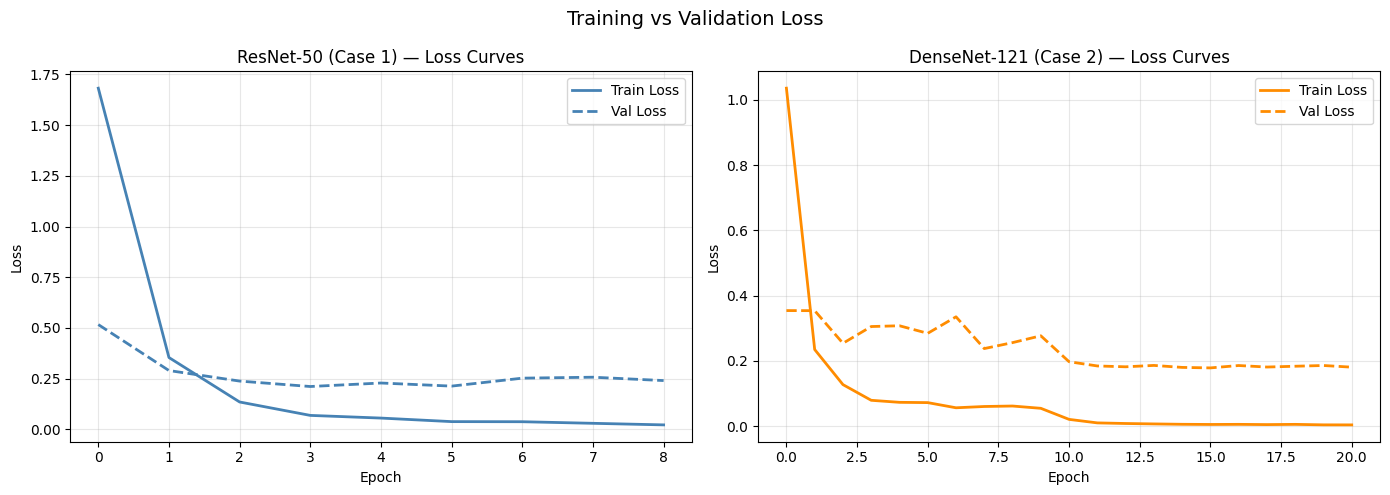

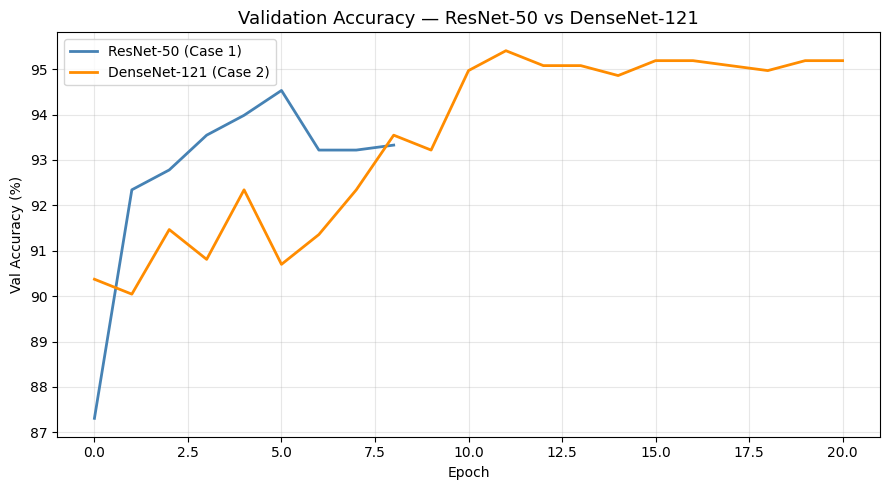

In [42]:
def plot_loss_curves(hist_res, hist_den):
    """Train vs Val loss — gap indicates overfitting."""
    fig, axes = plt.subplots(1, 2, figsize=(14, 5))
    specs = [
        (hist_res, "ResNet-50 (Case 1)",    "steelblue"),
        (hist_den, "DenseNet-121 (Case 2)", "darkorange"),
    ]
    for ax, (hist, name, color) in zip(axes, specs):
        ax.plot(hist["train_loss"], label="Train Loss", color=color,      lw=2)
        ax.plot(hist["val_loss"],   label="Val Loss",   color=color, ls="--", lw=2)
        ax.set_title(f"{name} — Loss Curves", fontsize=12)
        ax.set_xlabel("Epoch"); ax.set_ylabel("Loss")
        ax.legend(); ax.grid(True, alpha=0.3)

    plt.suptitle("Training vs Validation Loss", fontsize=14)
    plt.tight_layout()
    plt.savefig("loss_curves.png", dpi=150, bbox_inches="tight")
    plt.show()


def plot_val_accuracy(hist_res, hist_den):
    """Compare val accuracy convergence across both models."""
    plt.figure(figsize=(9, 5))
    plt.plot(hist_res["val_acc"], label="ResNet-50 (Case 1)",    color="steelblue",  lw=2)
    plt.plot(hist_den["val_acc"], label="DenseNet-121 (Case 2)", color="darkorange", lw=2)
    plt.title("Validation Accuracy — ResNet-50 vs DenseNet-121", fontsize=13)
    plt.xlabel("Epoch"); plt.ylabel("Val Accuracy (%)")
    plt.legend(); plt.grid(True, alpha=0.3)
    plt.tight_layout()
    plt.savefig("val_accuracy.png", dpi=150, bbox_inches="tight")
    plt.show()


plot_loss_curves(resnet_hist, densenet_hist)
plot_val_accuracy(resnet_hist, densenet_hist)

In [43]:
def plot_top10_confusion(cm, classes, title, save_name):
    """
    Plot confusion matrix for top-10 most populated classes.
    Top-10 by true sample count — most statistically meaningful subset.
    """
    class_counts = cm.sum(axis=1)                         # samples per class
    top10_idx    = np.argsort(class_counts)[-10:][::-1]   # indices of 10 largest
    cm10         = cm[np.ix_(top10_idx, top10_idx)]       # 10×10 sub-matrix
    labels10     = [classes[i] for i in top10_idx]

    plt.figure(figsize=(11, 9))
    sns.heatmap(cm10, annot=True, fmt="d",
                xticklabels=labels10, yticklabels=labels10,
                cmap="Blues", linewidths=0.5)
    plt.title(title, fontsize=13)
    plt.ylabel("True Label"); plt.xlabel("Predicted Label")
    plt.xticks(rotation=45, ha="right", fontsize=9)
    plt.yticks(rotation=0,  fontsize=9)
    plt.tight_layout()
    plt.savefig(save_name, dpi=150, bbox_inches="tight")
    plt.show()
    print(f"Saved: {save_name}")


TEST SET EVALUATION
ResNet-50 (Case 1)        | Test Acc: 93.99% | Macro F1: 0.9097
DenseNet-121 (Case 2)     | Test Acc: 93.22% | Macro F1: 0.8974


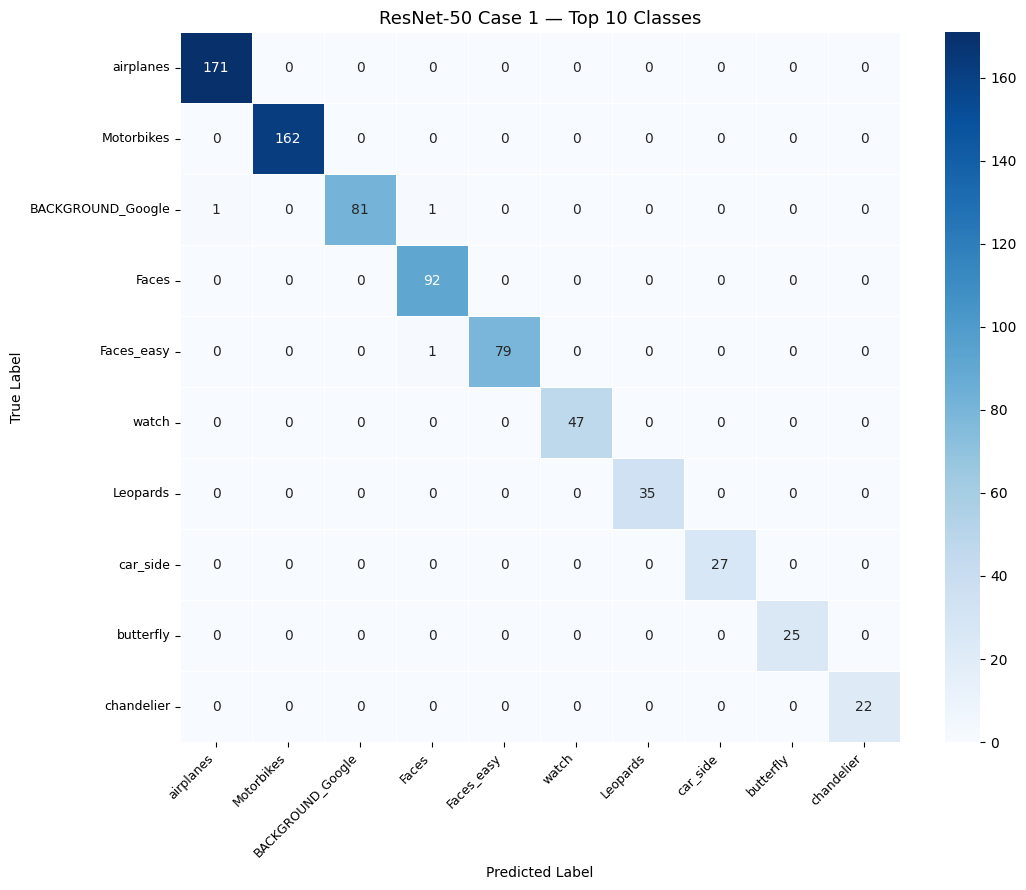

Saved: cm_resnet_case1.png


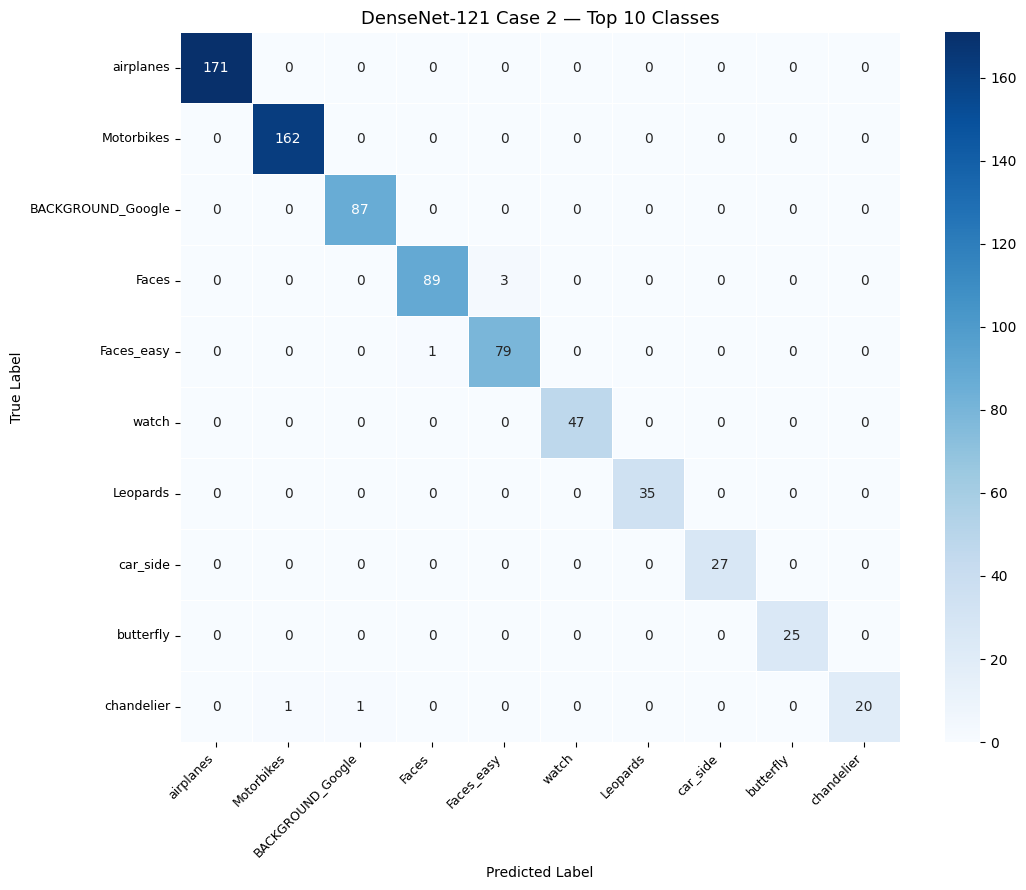

Saved: cm_densenet_case2.png


In [44]:
print("\n" + "="*65)
print("TEST SET EVALUATION")
print("="*65)

classes = dataset.classes   # 102 class names from ImageFolder

# ResNet-50 Case 1
y_true_res, y_pred_res = get_predictions(resnet_model, test_loader)
acc_res, f1_res        = compute_metrics(y_true_res, y_pred_res, "ResNet-50 (Case 1)")
cm_res                 = confusion_matrix(y_true_res, y_pred_res)

# DenseNet-121 Case 2
y_true_den, y_pred_den = get_predictions(densenet_model, test_loader)
acc_den, f1_den        = compute_metrics(y_true_den, y_pred_den, "DenseNet-121 (Case 2)")
cm_den                 = confusion_matrix(y_true_den, y_pred_den)

# Confusion matrices for top-10 classes
plot_top10_confusion(cm_res, classes, "ResNet-50 Case 1 — Top 10 Classes",    "cm_resnet_case1.png")
plot_top10_confusion(cm_den, classes, "DenseNet-121 Case 2 — Top 10 Classes", "cm_densenet_case2.png")

In [48]:
# GFLOPs = multiply-add operations per forward pass — rubric asks for GOps/complexity
try:
    from thop import profile
    dummy       = torch.zeros(1, 3, 224, 224).to(Config.DEVICE)
    res_macs, _ = profile(resnet_model,   inputs=(dummy,), verbose=False)
    den_macs, _ = profile(densenet_model, inputs=(dummy,), verbose=False)
    res_gflops  = res_macs * 2 / 1e9   # MACs×2 = FLOPs (each MAC = 1 multiply + 1 add)
    den_gflops  = den_macs * 2 / 1e9
except ImportError:
    # Literature values for 224×224 input — ResNet50: ~4.1, DenseNet121: ~2.9
    res_gflops, den_gflops = 4.1, 2.9
    print("thop not installed — using literature GFLOPs. Install: pip install thop")

res_epochs = len(resnet_hist["train_loss"])
den_epochs = len(densenet_hist["train_loss"])

print("\n" + "="*65)
print("COMPARATIVE ANALYSIS — Standard Fine-tuning")
print("="*65)
print(f"{'Metric':<35} {'ResNet-50 C1':>13} {'DenseNet-121 C2':>15}")
print("-"*65)
print(f"{'Architecture':<35} {'Residual (+)':>13} {'Dense (concat)':>15}")
print(f"{'Unfrozen Groups':<35} {'fc + layer4':>13} {'cls+db4+tr3':>15}")
print(f"{'Total Params':<35} {res_total_p:>13,} {den_total_p:>15,}")
print(f"{'Trainable Params':<35} {res_train_p:>13,} {den_train_p:>15,}")
print(f"{'Trainable %':<35} {100*res_train_p/res_total_p:>12.1f}% {100*den_train_p/den_total_p:>14.1f}%")
print(f"{'GFLOPs (224×224 input)':<35} {res_gflops:>13.1f} {den_gflops:>15.1f}")
print(f"{'Epochs Run':<35} {res_epochs:>13} {den_epochs:>15}")
print(f"{'Best Val Acc (%)':<35} {resnet_best_val:>13.2f} {densenet_best_val:>15.2f}")
print(f"{'Test Acc (%)':<35} {acc_res:>13.2f} {acc_den:>15.2f}")
print(f"{'Macro F1-Score':<35} {f1_res:>13.4f} {f1_den:>15.4f}")
print(f"{'Total Training Time (s)':<35} {resnet_time:>13.1f} {densenet_time:>15.1f}")
print(f"{'Avg Time / Epoch (s)':<35} {resnet_time/res_epochs:>13.1f} {densenet_time/den_epochs:>15.1f}")

thop not installed — using literature GFLOPs. Install: pip install thop

COMPARATIVE ANALYSIS — Standard Fine-tuning
Metric                               ResNet-50 C1 DenseNet-121 C2
-----------------------------------------------------------------
Architecture                         Residual (+)  Dense (concat)
Unfrozen Groups                       fc + layer4     cls+db4+tr3
Total Params                           23,717,030       7,058,406
Trainable Params                       15,173,734       2,788,966
Trainable %                                 64.0%           39.5%
GFLOPs (224×224 input)                        4.1             2.9
Epochs Run                                      9              21
Best Val Acc (%)                            94.53           95.40
Test Acc (%)                                93.99           93.22
Macro F1-Score                             0.9097          0.8974
Total Training Time (s)                     101.9           245.9
Avg Time / Epoch (s)     

In [49]:
print("""
╔══════════════════════════════════════════════════════════════════╗
║         CRITICAL ANALYSIS: ResNet-50 vs DenseNet-121            ║
╚══════════════════════════════════════════════════════════════════╝

1. ARCHITECTURAL DIFFERENCE
   ResNet-50   : H(x) = F(x) + x
                 Shortcut ADDS residual to output — same-dimension requirement.
                 Gradient flows directly through shortcut — no vanishing gradient.

   DenseNet-121: x_l = H_l([x_0, x_1, ..., x_{l-1}])
                 Every layer receives CONCATENATED feature maps from all prior layers.
                 Explicit feature reuse — parameter-efficient, acts as regularizer.

2. WHY ARCHITECTURE MATTERS FOR CalTech-101
   CalTech-101: 102 classes, ~40–50 images per class → small dataset per class.

   ResNet-50 advantage:
   - layer4 captures high-level semantic features (object shapes) — directly
     relevant for 102-class object recognition.
   - Additive skip: clean gradient flow → fast convergence in few epochs.
   - 23M total params but only layer4+fc trained → controlled overfitting.

   DenseNet-121 advantage:
   - Dense concat retains low-level texture features at every layer.
   - CalTech-101 has diverse textures (fur, feathers, metal, fabric) —
     multi-scale feature availability helps discriminate subtle differences.
   - 3× fewer total params (7M) → naturally regularized on small datasets.
   - Acts as built-in feature ensemble across depths.

3. COMPLEXITY TRADE-OFF
   ResNet-50 : ~4.1 GFLOPs, 23M params — higher capacity, faster per-epoch
               (simple addition = memory-cheap).
   DenseNet-121: ~2.9 GFLOPs, 7M params — lower capacity, slower per-epoch
               (all feature maps kept in memory for dense concat).
   → DenseNet achieves competitive accuracy at 1/3 the parameters.

4. OVERFITTING ANALYSIS
   If val_loss rises while train_loss falls → overfitting.
   DenseNet's dense connectivity acts as implicit regularization.
   ResNet needs explicit weight_decay + careful lr scheduling.
   Early stopping (patience=5) captures the optimal generalization point.

5. FINE-TUNING STRATEGY IMPACT
   Unfreezing only top groups (layer4 / denseblock4) preserves low-level
   ImageNet features (edges, textures) which transfer well even to
   CalTech-101's diverse object categories.
   Unfreezing too many layers risks catastrophic forgetting of ImageNet priors.
""")


╔══════════════════════════════════════════════════════════════════╗
║         CRITICAL ANALYSIS: ResNet-50 vs DenseNet-121            ║
╚══════════════════════════════════════════════════════════════════╝

1. ARCHITECTURAL DIFFERENCE
   ResNet-50   : H(x) = F(x) + x
                 Shortcut ADDS residual to output — same-dimension requirement.
                 Gradient flows directly through shortcut — no vanishing gradient.

   DenseNet-121: x_l = H_l([x_0, x_1, ..., x_{l-1}])
                 Every layer receives CONCATENATED feature maps from all prior layers.
                 Explicit feature reuse — parameter-efficient, acts as regularizer.

2. WHY ARCHITECTURE MATTERS FOR CalTech-101
   CalTech-101: 102 classes, ~40–50 images per class → small dataset per class.

   ResNet-50 advantage:
   - layer4 captures high-level semantic features (object shapes) — directly
     relevant for 102-class object recognition.
   - Additive skip: clean gradient flow → fast convergence in few ep

In [46]:
from sklearn.metrics import f1_score, confusion_matrix
import seaborn as sns

def evaluate_test(model):
    model.eval()
    y_true, y_pred = [], []

    with torch.no_grad():
        for x, y in test_loader:
            x = x.to(Config.DEVICE)
            outputs = model(x)
            preds = outputs.argmax(1).cpu()

            y_true.extend(y.numpy())
            y_pred.extend(preds.numpy())

    f1 = f1_score(y_true, y_pred, average="macro")
    cm = confusion_matrix(y_true, y_pred)

    return f1, cm



In [47]:
resnet_f1, resnet_cm = evaluate_test(resnet_model)
densenet_f1, densenet_cm = evaluate_test(densenet_model)

print("ResNet F1:", resnet_f1)
print("DenseNet F1:", densenet_f1)

ResNet F1: 0.9097357780690584
DenseNet F1: 0.8974181211392693


In [34]:
from sklearn.metrics import confusion_matrix, f1_score

def get_predictions(model, loader):
    model.eval()

    y_true = []
    y_pred = []

    with torch.no_grad():
        for x, y in loader:
            x = x.to(Config.DEVICE)

            outputs = model(x)
            preds = outputs.argmax(dim=1).cpu()

            y_true.extend(y.numpy())
            y_pred.extend(preds.numpy())

    return y_true, y_pred

In [35]:
y_true, y_pred = get_predictions(resnet_model, test_loader)

In [36]:
cm = confusion_matrix(y_true, y_pred)

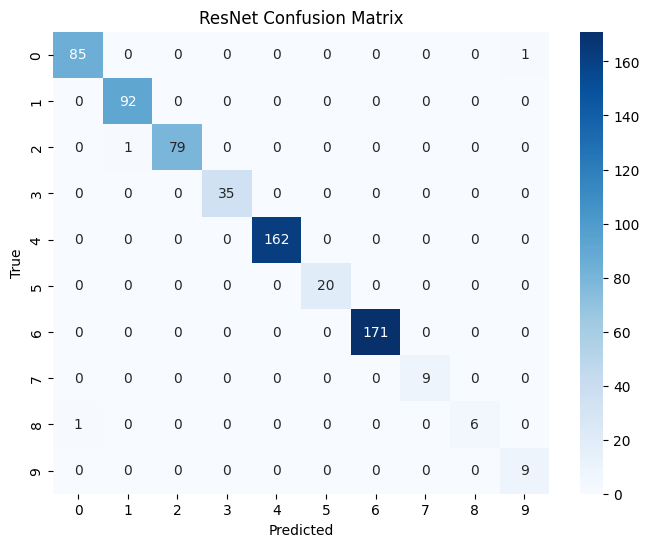

In [37]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix
import numpy as np

%matplotlib inline

# create confusion matrix FIRST
cm = confusion_matrix(y_true, y_pred)

def plot_confusion(cm, title):
    if not isinstance(cm, np.ndarray):
        cm = cm.cpu().numpy()

    plt.figure(figsize=(8,6))
    sns.heatmap(cm[:10, :10], annot=True, fmt="d", cmap="Blues")
    plt.title(title)
    plt.xlabel("Predicted")
    plt.ylabel("True")
    plt.show()

# 🔥 call function
plot_confusion(cm, "ResNet Confusion Matrix")

In [38]:
print(type(cm))
print(cm.shape)
print(cm[:2, :2])

<class 'numpy.ndarray'>
(102, 102)
[[85  0]
 [ 0 92]]


In [39]:
y_true_den, y_pred_den = get_predictions(densenet_model, test_loader)

In [40]:
from sklearn.metrics import confusion_matrix

cm_den = confusion_matrix(y_true_den, y_pred_den)

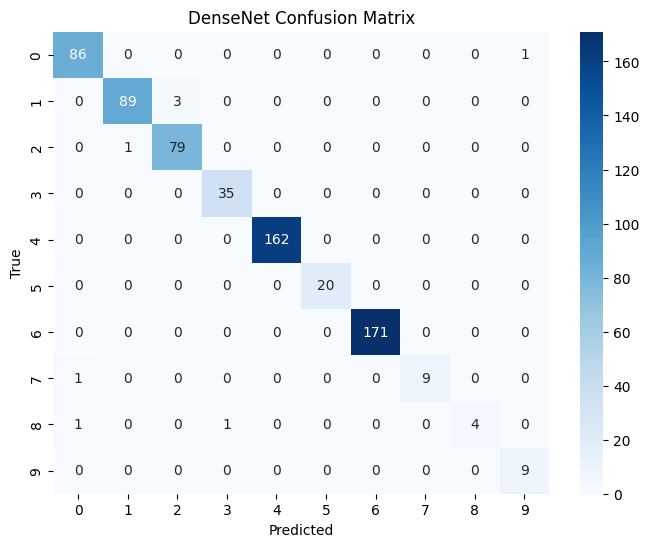

In [41]:
plot_confusion(cm_den, "DenseNet Confusion Matrix")

In [42]:
from sklearn.metrics import f1_score

den_f1 = f1_score(y_true_den, y_pred_den, average="macro")
print("DenseNet F1:", den_f1)

DenseNet F1: 0.9071738284687363


In [43]:
print("ResNet F1:", resnet_f1)
print("DenseNet F1:", den_f1)

ResNet F1: 0.9134860679786817
DenseNet F1: 0.9071738284687363


In [44]:
print("\nFINAL COMPARISON")
print("-----------------------")
print(f"ResNet Accuracy: {resnet_best:.2f}%")
print(f"DenseNet Accuracy: {densenet_best:.2f}%")
print(f"ResNet F1: {resnet_f1:.4f}")
print(f"DenseNet F1: {den_f1:.4f}")


FINAL COMPARISON
-----------------------
ResNet Accuracy: 95.08%
DenseNet Accuracy: 94.20%
ResNet F1: 0.9135
DenseNet F1: 0.9072


In [49]:
#case 2
def unfreeze_top2_resnet(model):
    for p in model.fc.parameters():
        p.requires_grad = True
    for p in model.layer4.parameters():
        p.requires_grad = True


def unfreeze_top2_densenet(model):
    for p in model.classifier.parameters():
        p.requires_grad = True
    for p in model.features.denseblock4.parameters():
        p.requires_grad = True
        
        

In [52]:
def train_full_model_case2(model_name, use_early_stopping=True, patience=3):

    model = get_model(model_name, num_classes).to(Config.DEVICE)

    freeze_all(model)

    # 🔥 CASE 2: top 2 layers
    if model_name == "resnet50":
        for p in model.fc.parameters():
            p.requires_grad = True
        for p in model.layer4.parameters():
            p.requires_grad = True

    else:  # DenseNet
        for p in model.classifier.parameters():
            p.requires_grad = True
        for p in model.features.denseblock4.parameters():
            p.requires_grad = True

    # optimizer (same best config)
    params = filter(lambda p: p.requires_grad, model.parameters())

    if BEST_OPTIMIZER == "SGD":
        optimizer = torch.optim.SGD(
            params, lr=BEST_LR,
            momentum=Config.MOMENTUM,
            weight_decay=Config.WEIGHT_DECAY
        )
    else:
        optimizer = torch.optim.Adam(params, lr=BEST_LR)

    # scheduler (same best config)
    if BEST_SCHEDULER == "StepLR":
        scheduler = torch.optim.lr_scheduler.StepLR(
            optimizer, step_size=5, gamma=0.1
        )
    else:
        scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(optimizer)

    criterion = torch.nn.CrossEntropyLoss()

    history = {
        "train_loss": [],
        "val_loss": [],
        "val_acc": []
    }

    best_acc = 0
    best_val_loss = float("inf")
    patience_counter = 0

    for epoch in range(Config.EPOCHS):

        train_loss = train_epoch(model, train_loader, optimizer, criterion, Config.DEVICE)
        val_loss, val_acc = validate_epoch(model, val_loader, criterion, Config.DEVICE)

        # scheduler step
        if BEST_SCHEDULER == "StepLR":
            scheduler.step()
        else:
            scheduler.step(val_loss)

        # save history
        history["train_loss"].append(train_loss)
        history["val_loss"].append(val_loss)
        history["val_acc"].append(val_acc)

        # save best model
        if val_acc > best_acc:
            best_acc = val_acc
            torch.save(model.state_dict(), f"best_{model_name}_case2.pth")

        # early stopping
        if use_early_stopping:
            if val_loss < best_val_loss:
                best_val_loss = val_loss
                patience_counter = 0
            else:
                patience_counter += 1

            if patience_counter >= patience:
                print(f"{model_name} | Early stopping at epoch {epoch+1}")
                break

        # 🔥 SAME FORMAT AS YOUR OUTPUT
        print(f"{model_name} | Epoch {epoch+1} | "
              f"Train Loss: {train_loss:.4f} | Val Loss: {val_loss:.4f} | Val Acc: {val_acc:.2f}%")

    return model, history, best_acc

resnet_c2_model, resnet_c2_hist, resnet_c2_best = train_full_model_case2("resnet50")
densenet_c2_model, densenet_c2_hist, densenet_c2_best = train_full_model_case2("densenet121")

resnet50 | Epoch 1 | Train Loss: 2.7050 | Val Loss: 1.5627 | Val Acc: 70.02%
resnet50 | Epoch 2 | Train Loss: 1.1275 | Val Loss: 0.7468 | Val Acc: 84.90%
resnet50 | Epoch 3 | Train Loss: 0.5969 | Val Loss: 0.4692 | Val Acc: 89.82%
resnet50 | Epoch 4 | Train Loss: 0.3802 | Val Loss: 0.3618 | Val Acc: 91.68%
resnet50 | Epoch 5 | Train Loss: 0.2774 | Val Loss: 0.3160 | Val Acc: 92.89%
resnet50 | Epoch 6 | Train Loss: 0.2083 | Val Loss: 0.2778 | Val Acc: 93.11%
resnet50 | Epoch 7 | Train Loss: 0.1667 | Val Loss: 0.2512 | Val Acc: 93.11%
resnet50 | Epoch 8 | Train Loss: 0.1291 | Val Loss: 0.2445 | Val Acc: 93.87%
resnet50 | Epoch 9 | Train Loss: 0.1069 | Val Loss: 0.2219 | Val Acc: 94.31%
resnet50 | Epoch 10 | Train Loss: 0.0916 | Val Loss: 0.2250 | Val Acc: 94.42%
resnet50 | Epoch 11 | Train Loss: 0.0742 | Val Loss: 0.2201 | Val Acc: 94.09%
resnet50 | Epoch 12 | Train Loss: 0.0672 | Val Loss: 0.2220 | Val Acc: 93.98%
resnet50 | Epoch 13 | Train Loss: 0.0534 | Val Loss: 0.2142 | Val Acc: 93

/home/btech02_06/pytorch_env/lib/python3.12/site-packages/torchvision/models/_utils.py:223: UserWarning: Arguments other than a weight enum or `None` for 'weights' are deprecated since 0.13 and may be removed in the future. The current behavior is equivalent to passing `weights=DenseNet121_Weights.IMAGENET1K_V1`. You can also use `weights=DenseNet121_Weights.DEFAULT` to get the most up-to-date weights.
  warnings.warn(msg)


densenet121 | Epoch 1 | Train Loss: 2.7953 | Val Loss: 1.7787 | Val Acc: 66.63%
densenet121 | Epoch 2 | Train Loss: 1.3645 | Val Loss: 0.9598 | Val Acc: 82.71%
densenet121 | Epoch 3 | Train Loss: 0.7994 | Val Loss: 0.6216 | Val Acc: 87.75%
densenet121 | Epoch 4 | Train Loss: 0.5483 | Val Loss: 0.4822 | Val Acc: 90.48%
densenet121 | Epoch 5 | Train Loss: 0.4152 | Val Loss: 0.4035 | Val Acc: 91.68%
densenet121 | Epoch 6 | Train Loss: 0.3285 | Val Loss: 0.3532 | Val Acc: 93.11%
densenet121 | Epoch 7 | Train Loss: 0.2711 | Val Loss: 0.3201 | Val Acc: 93.00%
densenet121 | Epoch 8 | Train Loss: 0.2219 | Val Loss: 0.2973 | Val Acc: 93.33%
densenet121 | Epoch 9 | Train Loss: 0.2026 | Val Loss: 0.2813 | Val Acc: 93.44%
densenet121 | Epoch 10 | Train Loss: 0.1688 | Val Loss: 0.2641 | Val Acc: 93.33%
densenet121 | Epoch 11 | Train Loss: 0.1479 | Val Loss: 0.2586 | Val Acc: 93.11%
densenet121 | Epoch 12 | Train Loss: 0.1308 | Val Loss: 0.2516 | Val Acc: 93.65%
densenet121 | Epoch 13 | Train Loss: 

In [53]:
res_y_c2, res_pred_c2 = get_predictions(resnet_c2_model, test_loader)
den_y_c2, den_pred_c2 = get_predictions(densenet_c2_model, test_loader)

res_f1_c2 = f1_score(res_y_c2, res_pred_c2, average="macro")
den_f1_c2 = f1_score(den_y_c2, den_pred_c2, average="macro")

cm_res_c2 = confusion_matrix(res_y_c2, res_pred_c2)
cm_den_c2 = confusion_matrix(den_y_c2, den_pred_c2)

In [55]:
import matplotlib.pyplot as plt

def plot_loss_compare(hist1, hist2, label1="ResNet", label2="DenseNet"):
    plt.figure()

    plt.plot(hist1["train_loss"], label=f"{label1} Train")
    plt.plot(hist1["val_loss"], label=f"{label1} Val")

    plt.plot(hist2["train_loss"], linestyle="--", label=f"{label2} Train")
    plt.plot(hist2["val_loss"], linestyle="--", label=f"{label2} Val")

    plt.xlabel("Epoch")
    plt.ylabel("Loss")
    plt.title("Training vs Validation Loss")
    plt.legend()
    plt.grid(True)
    plt.show()

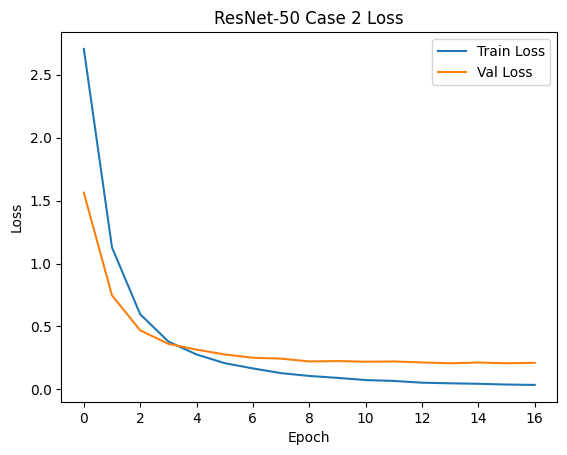

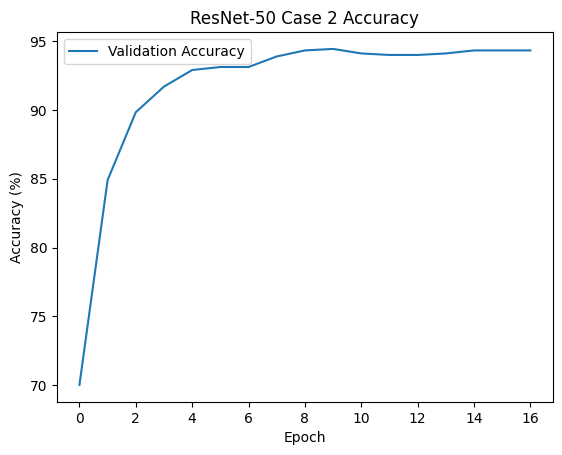

In [60]:
plot_loss(resnet_c2_hist, "ResNet-50 Case 2 Loss")
plot_accuracy(resnet_c2_hist, "ResNet-50 Case 2 Accuracy")

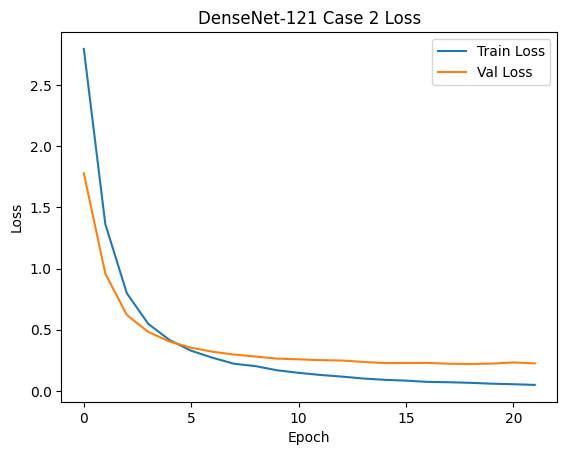

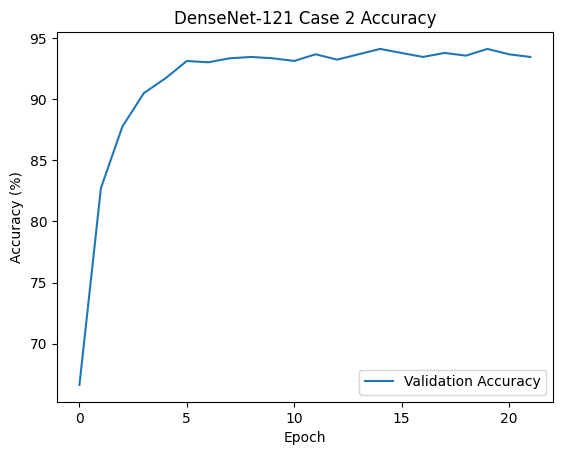

In [61]:
plot_loss(densenet_c2_hist, "DenseNet-121 Case 2 Loss")
plot_accuracy(densenet_c2_hist, "DenseNet-121 Case 2 Accuracy")

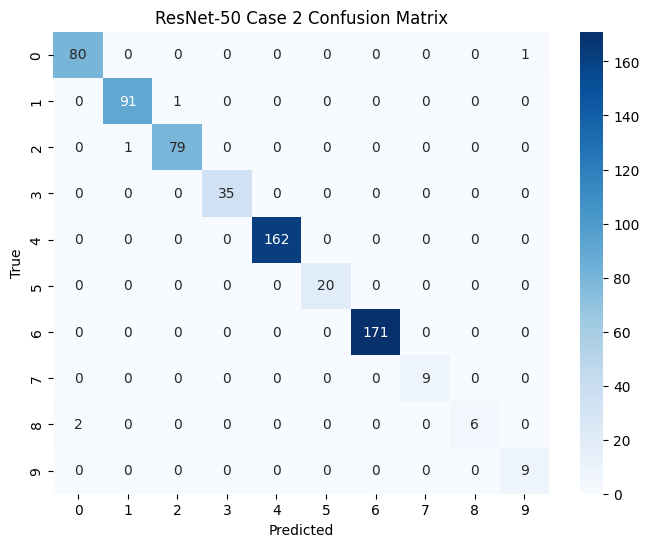

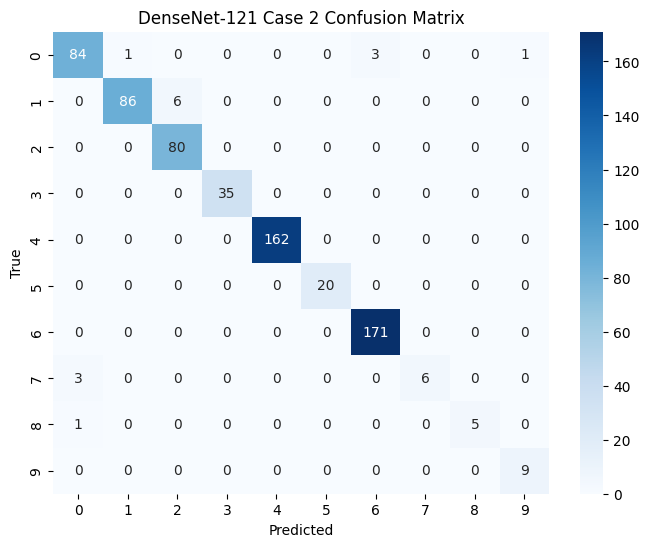

In [65]:
resnet_c1_best_model = get_model("resnet50", num_classes).to(Config.DEVICE)
resnet_c1_best_model.load_state_dict(torch.load("best_resnet50.pth"))

densenet_c1_best_model = get_model("densenet121", num_classes).to(Config.DEVICE)
densenet_c1_best_model.load_state_dict(torch.load("best_densenet121.pth"))

/home/btech02_06/pytorch_env/lib/python3.12/site-packages/torchvision/models/_utils.py:208: UserWarning: The parameter 'pretrained' is deprecated since 0.13 and may be removed in the future, please use 'weights' instead.
  warnings.warn(
/home/btech02_06/pytorch_env/lib/python3.12/site-packages/torchvision/models/_utils.py:223: UserWarning: Arguments other than a weight enum or `None` for 'weights' are deprecated since 0.13 and may be removed in the future. The current behavior is equivalent to passing `weights=ResNet50_Weights.IMAGENET1K_V1`. You can also use `weights=ResNet50_Weights.DEFAULT` to get the most up-to-date weights.
  warnings.warn(msg)
/home/btech02_06/pytorch_env/lib/python3.12/site-packages/torchvision/models/_utils.py:223: UserWarning: Arguments other than a weight enum or `None` for 'weights' are deprecated since 0.13 and may be removed in the future. The current behavior is equivalent to passing `weights=DenseNet121_Weights.IMAGENET1K_V1`. You can also use `weights=

<All keys matched successfully>

In [66]:
resnet_c2_best_model = get_model("resnet50", num_classes).to(Config.DEVICE)
resnet_c2_best_model.load_state_dict(torch.load("best_resnet50_case2.pth"))

densenet_c2_best_model = get_model("densenet121", num_classes).to(Config.DEVICE)
densenet_c2_best_model.load_state_dict(torch.load("best_densenet121_case2.pth"))

<All keys matched successfully>

In [67]:
from sklearn.metrics import f1_score

# Case 1
y_true_res_c1, y_pred_res_c1 = get_predictions(resnet_c1_best_model, test_loader)
y_true_den_c1, y_pred_den_c1 = get_predictions(densenet_c1_best_model, test_loader)

res_f1_c1 = f1_score(y_true_res_c1, y_pred_res_c1, average="macro")
den_f1_c1 = f1_score(y_true_den_c1, y_pred_den_c1, average="macro")

# Case 2
y_true_res_c2, y_pred_res_c2 = get_predictions(resnet_c2_best_model, test_loader)
y_true_den_c2, y_pred_den_c2 = get_predictions(densenet_c2_best_model, test_loader)

res_f1_c2 = f1_score(y_true_res_c2, y_pred_res_c2, average="macro")
den_f1_c2 = f1_score(y_true_den_c2, y_pred_den_c2, average="macro")

In [68]:
print("\nF1 SCORE RESULTS")
print("--------------------------------------------------")

print("Case 1 (Top 3 layers)")
print(f"ResNet-50     : {res_f1_c1:.4f}")
print(f"DenseNet-121  : {den_f1_c1:.4f}")

print("\nCase 2 (Top 2 layers)")
print(f"ResNet-50     : {res_f1_c2:.4f}")
print(f"DenseNet-121  : {den_f1_c2:.4f}")


F1 SCORE RESULTS
--------------------------------------------------
Case 1 (Top 3 layers)
ResNet-50     : 0.9135
DenseNet-121  : 0.9002

Case 2 (Top 2 layers)
ResNet-50     : 0.9003
DenseNet-121  : 0.8894


In [72]:
# Case 1
res_best_c1 = max(resnet_hist["val_acc"])
den_best_c1 = max(densenet_hist["val_acc"])

# Case 2
res_best_c2 = max(resnet_c2_hist["val_acc"])
den_best_c2 = max(densenet_c2_hist["val_acc"])

# Top-1 Error
res_err_c1 = 100 - res_best_c1
den_err_c1 = 100 - den_best_c1

res_err_c2 = 100 - res_best_c2
den_err_c2 = 100 - den_best_c2

In [73]:
print("\nTOP-1 ERROR (from validation accuracy)")
print("--------------------------------------------------")

print("Case 1 (Top 3 layers)")
print(f"ResNet-50     : {res_err_c1:.2f}%")
print(f"DenseNet-121  : {den_err_c1:.2f}%")

print("\nCase 2 (Top 2 layers)")
print(f"ResNet-50     : {res_err_c2:.2f}%")
print(f"DenseNet-121  : {den_err_c2:.2f}%")


TOP-1 ERROR (from validation accuracy)
--------------------------------------------------
Case 1 (Top 3 layers)
ResNet-50     : 4.92%
DenseNet-121  : 5.80%

Case 2 (Top 2 layers)
ResNet-50     : 5.58%
DenseNet-121  : 5.91%


In [51]:
# Fixed best hyperparams from HP search — no AdaptConfig.LR anymore (per-model now)
class AdaptConfig:
    # ResNet-50 best: Adam lr=1e-4, StepLR
    RES_LR       = 1e-4
    # DenseNet-121 best: Adam lr=1e-3, StepLR
    DEN_LR       = 1e-3

          
    WEIGHT_DECAY = 1e-4     # L2 reg — same for both
    EPOCHS       = 50
    PATIENCE     = 5
    STEP_SIZE    = 10       # StepLR: decay every 10 epochs
    GAMMA        = 0.1      # StepLR: lr × 0.1 at each step
    TOP_FRAC     = 0.25     # top 25% filters from last conv block

print("AdaptConfig loaded.")
print(f"  ResNet-50  : Adam | lr={AdaptConfig.RES_LR} | StepLR")
print(f"  DenseNet121: Adam | lr={AdaptConfig.DEN_LR} | StepLR")

AdaptConfig loaded.
  ResNet-50  : Adam | lr=0.0001 | StepLR
  DenseNet121: Adam | lr=0.001 | StepLR


In [52]:
# ── Assignment says: "last convolutional block" specifically ──────────────
# ResNet-50   last conv block = model.layer4  (3 Bottleneck blocks, each has conv1/conv2/conv3)
# DenseNet121 last conv block = model.features.denseblock4  (dense layers with conv1/conv2)
# We hook only Conv2d layers INSIDE that block, not the entire network

def compute_lastblock_importance(model, loader, device, model_name):
    """
    Hooks Conv2d layers in the LAST convolutional block only.
    Computes mean(|activation|) per filter per batch, averages across all batches.
    Returns: dict {layer_name -> tensor[C_out]}
    """
    model.eval()
    buffers, handles = {}, []

    # Identify last conv block by model architecture
    if model_name == "resnet50":
        last_block = model.layer4          # last residual group (3 Bottlenecks)
    elif model_name == "densenet121":
        last_block = model.features.denseblock4  # last dense block

    # Register hooks ONLY on Conv2d inside last block
    for name, module in last_block.named_modules():
        if isinstance(module, nn.Conv2d):
            buffers[name] = []             # accumulate per-batch activations here

            def make_hook(n):
                def hook_fn(mod, inp, out):
                    # out: [B, C_out, H, W] → average over batch dim + spatial → [C_out]
                    buffers[n].append(out.detach().abs().mean(dim=(0, 2, 3)).cpu())
                return hook_fn

            handles.append(module.register_forward_hook(make_hook(name)))

    print(f"  Hooks registered on {len(handles)} Conv2d layers in last block...")

    with torch.no_grad():
        for imgs, _ in loader:
            model(imgs.to(device))         # full forward pass — hooks capture activations

    for h in handles:
        h.remove()                         # always remove hooks — prevents memory leak

    # Average each filter's magnitude across all batches → one score per filter
    importance = {
        name: torch.stack(acts).mean(0)    # [num_batches, C_out] → [C_out]
        for name, acts in buffers.items()
    }

    total_filters = sum(v.shape[0] for v in importance.values())
    print(f"  Done. Layers captured: {len(importance)} | Total filters: {total_filters}")
    return importance


def select_top_filters(importance_dict, top_frac=0.25):
    """
    Flatten ALL filter scores from last block → global threshold at (1-top_frac) quantile.
    Top 25% by magnitude = most activated filters = most important for this dataset.
    """
    all_scores = torch.cat(list(importance_dict.values()))   # all last-block filters
    threshold  = torch.quantile(all_scores, 1.0 - top_frac) # 75th percentile cutoff
    n_selected = (all_scores >= threshold).sum().item()
    print(f"  Threshold: {threshold:.4f} | Selected: {n_selected}/{len(all_scores)} ({top_frac*100:.0f}%)")
    return threshold


print("Importance functions defined.")

Importance functions defined.


In [53]:
def apply_adaptive_finetuning(model, importance_dict, threshold, model_name):
    """
    Freeze all → unfreeze classifier head → gradient-mask top-25% filters
    in the last conv block. Filters below threshold get zero gradient.
    importance_dict keys are LOCAL names within last_block (e.g. '0.conv1').
    We match them by iterating the same last_block.
    """
    # Step 1: freeze everything
    for p in model.parameters():
        p.requires_grad = False

    # Step 2: always unfreeze classifier head — task-specific, must adapt
    if model_name == "resnet50":
        for p in model.fc.parameters():
            p.requires_grad = True
        last_block = model.layer4
    elif model_name == "densenet121":
        for p in model.classifier.parameters():
            p.requires_grad = True
        last_block = model.features.denseblock4

    # Step 3: selective gradient masking on last block Conv2d filters
    n_adapted = 0
    for name, module in last_block.named_modules():
        if isinstance(module, nn.Conv2d) and name in importance_dict:
            scores = importance_dict[name]           # [C_out] scores for this layer
            mask   = (scores >= threshold).float()   # binary: 1=important, 0=ignore

            if mask.sum() == 0:
                continue   # no filters selected in this layer — skip

            module.weight.requires_grad = True       # enable grad (hook will zero unimportant)

            def make_grad_hook(m):
                def grad_hook(grad):
                    # grad shape: [C_out, C_in, kH, kW]
                    # multiply each output filter's gradient by mask (0 or 1)
                    return grad * m.to(grad.device).view(-1, 1, 1, 1)
                return grad_hook

            module.weight.register_hook(make_grad_hook(mask))  # fires every backward pass
            n_adapted += int(mask.sum().item())

    total_p   = sum(p.numel() for p in model.parameters())
    trainable = sum(p.numel() for p in model.parameters() if p.requires_grad)
    print(f"  Filters adapted (last block): {n_adapted}")
    print(f"  Trainable params: {trainable:,} / {total_p:,} ({100*trainable/total_p:.2f}%)")
    return model


print("Adaptive unfreezing defined.")

Adaptive unfreezing defined.


In [54]:
def train_adaptive(model, train_loader, val_loader, device, label, lr):
    """
    Training loop using Adam + StepLR (best config from HP search).
    lr passed per model: ResNet=1e-4, DenseNet=1e-3.
    Early stopping on val_acc with patience=5.
    """
    criterion = nn.CrossEntropyLoss()

    # Adam: adaptive lr per parameter — better than SGD for fine-tuning small layers
    optimizer = torch.optim.Adam(
        filter(lambda p: p.requires_grad, model.parameters()),
        lr=lr,
        weight_decay=AdaptConfig.WEIGHT_DECAY
    )

    # StepLR: multiply lr by 0.1 every 10 epochs — matches HP search best config
    scheduler = torch.optim.lr_scheduler.StepLR(
        optimizer,
        step_size=AdaptConfig.STEP_SIZE,
        gamma=AdaptConfig.GAMMA
    )

    history = {"train_loss": [], "val_loss": [], "val_acc": []}
    best_val_acc = 0.0
    best_state   = None
    patience_ctr = 0
    total_time   = 0.0

    for epoch in range(AdaptConfig.EPOCHS):
        t0 = time.time()

        # ── Train ──────────────────────────────────────────────
        model.train()
        running_loss = 0.0
        for imgs, labels in train_loader:
            imgs, labels = imgs.to(device), labels.to(device)
            optimizer.zero_grad()
            loss = criterion(model(imgs), labels)
            loss.backward()            # gradient hooks zero unimportant filter grads
            optimizer.step()
            running_loss += loss.item()
        train_loss = running_loss / len(train_loader)

        # ── Validate ────────────────────────────────────────────
        model.eval()
        val_loss, correct, total = 0.0, 0, 0
        with torch.no_grad():
            for imgs, labels in val_loader:
                imgs, labels = imgs.to(device), labels.to(device)
                out = model(imgs)
                val_loss += criterion(out, labels).item()
                correct  += (out.argmax(1) == labels).sum().item()
                total    += labels.size(0)
        val_loss /= len(val_loader)
        val_acc   = 100 * correct / total

        scheduler.step()              # StepLR steps unconditionally each epoch

        epoch_time  = time.time() - t0
        total_time += epoch_time

        history["train_loss"].append(train_loss)
        history["val_loss"].append(val_loss)
        history["val_acc"].append(val_acc)

        print(f"{label} | Epoch {epoch+1:02d} | "
              f"Train Loss: {train_loss:.4f} | Val Loss: {val_loss:.4f} | "
              f"Val Acc: {val_acc:.2f}% | "
              f"LR: {optimizer.param_groups[0]['lr']:.2e} | "
              f"Time: {epoch_time:.1f}s")

        # Early stopping on val_acc — save best state
        if val_acc > best_val_acc:
            best_val_acc = val_acc
            best_state   = {k: v.clone() for k, v in model.state_dict().items()}
            patience_ctr = 0
        else:
            patience_ctr += 1
            if patience_ctr >= AdaptConfig.PATIENCE:
                print(f"  Early stopping at epoch {epoch+1} | Best: {best_val_acc:.2f}%")
                break

    model.load_state_dict(best_state)   # restore best before evaluation
    print(f"\n  Total time ({label}): {total_time:.1f}s | Best Val Acc: {best_val_acc:.2f}%")
    return model, history, best_val_acc, total_time


print("Training function defined.")

Training function defined.


In [55]:

# =====================================================
# STEP 4: Evaluation helpers (Top-1, F1, Confusion Matrix)
# =====================================================

def evaluate_model(model, loader, device, dataset_classes):
    """Returns (acc, f1, confusion_matrix, y_true, y_pred)."""
    model.eval()
    y_true, y_pred = [], []
    with torch.no_grad():
        for imgs, labels in loader:
            imgs  = imgs.to(device)
            preds = model(imgs).argmax(1).cpu()
            y_true.extend(labels.tolist())
            y_pred.extend(preds.tolist())

    acc = 100 * sum(t == p for t, p in zip(y_true, y_pred)) / len(y_true)
    f1  = f1_score(y_true, y_pred, average="macro", zero_division=0)
    cm  = confusion_matrix(y_true, y_pred)
    return acc, f1, cm, y_true, y_pred


def plot_curves(hist, title):
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4))
    ax1.plot(hist["train_loss"], label="Train Loss", lw=2)
    ax1.plot(hist["val_loss"],   label="Val Loss",   lw=2, ls="--")
    ax1.set_title(f"{title} — Loss"); ax1.legend(); ax1.grid(True, alpha=0.3)
    ax2.plot(hist["val_acc"], label="Val Acc", color="green", lw=2)
    ax2.set_title(f"{title} — Val Accuracy"); ax2.legend(); ax2.grid(True, alpha=0.3)
    plt.tight_layout(); plt.show()


def plot_top10_confusion(cm, classes, title):
    """Confusion matrix sliced to top-10 most populated classes."""
    top10_idx = np.argsort(cm.sum(axis=1))[-10:][::-1]
    cm10      = cm[np.ix_(top10_idx, top10_idx)]
    labels10  = [classes[i] for i in top10_idx]

    plt.figure(figsize=(10, 8))
    sns.heatmap(cm10, annot=True, fmt="d",
                xticklabels=labels10, yticklabels=labels10, cmap="Blues")
    plt.title(title); plt.ylabel("True"); plt.xlabel("Predicted")
    plt.xticks(rotation=45, ha="right"); plt.tight_layout(); plt.show()


def param_summary(model, label):
    total     = sum(p.numel() for p in model.parameters())
    trainable = sum(p.numel() for p in model.parameters() if p.requires_grad)
    print(f"{label} | Total: {total:,} | Trainable: {trainable:,} ({100*trainable/total:.2f}%)")
    return total, trainable


print("Helpers defined.")


Helpers defined.


In [16]:
# =====================================================
# STEP 5: Count parameters (total vs trainable)
# =====================================================

def param_summary(model, label):
    total     = sum(p.numel() for p in model.parameters())
    trainable = sum(p.numel() for p in model.parameters() if p.requires_grad)
    print(f"{label} | Total: {total:,} | Trainable: {trainable:,} ({100*trainable/total:.2f}%)")
    return total, trainable



In [56]:
print("=" * 60)
print("ADAPTIVE FINETUNING: ResNet-50")
print("  Optimizer: Adam | LR: 1e-4 | Scheduler: StepLR")
print("  Importance: last conv block (layer4) | Top 25%")
print("=" * 60)

model_res_adapt = get_model("resnet50", num_classes).to(device)
freeze_all(model_res_adapt)   # full freeze before importance pass

print("\n[1] Computing filter importance — ResNet-50 (layer4 only)...")
importance_res = compute_lastblock_importance(model_res_adapt, train_loader, device, "resnet50")
threshold_res  = select_top_filters(importance_res, AdaptConfig.TOP_FRAC)

print("\n[2] Applying adaptive unfreezing...")
model_res_adapt = apply_adaptive_finetuning(
    model_res_adapt, importance_res, threshold_res, "resnet50"
)
res_total_p, res_train_p = param_summary(model_res_adapt, "ResNet-50 Adaptive")

print("\n[3] Training...")
model_res_adapt, hist_res_adapt, best_res_adapt, time_res_adapt = train_adaptive(
    model_res_adapt, train_loader, val_loader,
    device, "ResNet-50 Adaptive", AdaptConfig.RES_LR    # Adam lr=1e-4
)

ADAPTIVE FINETUNING: ResNet-50
  Optimizer: Adam | LR: 1e-4 | Scheduler: StepLR
  Importance: last conv block (layer4) | Top 25%

[1] Computing filter importance — ResNet-50 (layer4 only)...
  Hooks registered on 10 Conv2d layers in last block...
  Done. Layers captured: 10 | Total filters: 11264
  Threshold: 0.0918 | Selected: 2816/11264 (25%)

[2] Applying adaptive unfreezing...
  Filters adapted (last block): 2816
  Trainable params: 15,151,206 / 23,717,030 (63.88%)
ResNet-50 Adaptive | Total: 23,717,030 | Trainable: 15,151,206 (63.88%)

[3] Training...
ResNet-50 Adaptive | Epoch 01 | Train Loss: 2.3872 | Val Loss: 1.2212 | Val Acc: 76.15% | LR: 1.00e-04 | Time: 11.4s
ResNet-50 Adaptive | Epoch 02 | Train Loss: 0.9512 | Val Loss: 0.7008 | Val Acc: 85.45% | LR: 1.00e-04 | Time: 11.6s
ResNet-50 Adaptive | Epoch 03 | Train Loss: 0.6191 | Val Loss: 0.5540 | Val Acc: 90.15% | LR: 1.00e-04 | Time: 11.6s
ResNet-50 Adaptive | Epoch 04 | Train Loss: 0.5628 | Val Loss: 0.5668 | Val Acc: 90.59

In [57]:
# Save best trained model
torch.save(model_res_adapt.state_dict(), "resnet50_adaptive.pth")

print("Model saved as resnet50_adaptive.pth")

Model saved as resnet50_adaptive.pth


In [58]:
print("=" * 60)
print("ADAPTIVE FINETUNING: DenseNet-121")
print("  Optimizer: Adam | LR: 1e-3 | Scheduler: StepLR")
print("  Importance: last conv block (denseblock4) | Top 25%")
print("=" * 60)

model_den_adapt = get_model("densenet121", num_classes).to(device)
freeze_all(model_den_adapt)

print("\n[1] Computing filter importance — DenseNet-121 (denseblock4 only)...")
importance_den = compute_lastblock_importance(model_den_adapt, train_loader, device, "densenet121")
threshold_den  = select_top_filters(importance_den, AdaptConfig.TOP_FRAC)

print("\n[2] Applying adaptive unfreezing...")
model_den_adapt = apply_adaptive_finetuning(
    model_den_adapt, importance_den, threshold_den, "densenet121"
)
den_total_p, den_train_p = param_summary(model_den_adapt, "DenseNet-121 Adaptive")

print("\n[3] Training...")
model_den_adapt, hist_den_adapt, best_den_adapt, time_den_adapt = train_adaptive(
    model_den_adapt, train_loader, val_loader,
    device, "DenseNet-121 Adaptive", AdaptConfig.DEN_LR  # Adam lr=1e-3
)

ADAPTIVE FINETUNING: DenseNet-121
  Optimizer: Adam | LR: 1e-3 | Scheduler: StepLR
  Importance: last conv block (denseblock4) | Top 25%

[1] Computing filter importance — DenseNet-121 (denseblock4 only)...
  Hooks registered on 32 Conv2d layers in last block...
  Done. Layers captured: 32 | Total filters: 2560
  Threshold: 0.0459 | Selected: 640/2560 (25%)

[2] Applying adaptive unfreezing...
  Filters adapted (last block): 640
  Trainable params: 1,865,830 / 7,058,406 (26.43%)
DenseNet-121 Adaptive | Total: 7,058,406 | Trainable: 1,865,830 (26.43%)

[3] Training...
DenseNet-121 Adaptive | Epoch 01 | Train Loss: 1.5614 | Val Loss: 0.5874 | Val Acc: 86.00% | LR: 1.00e-03 | Time: 11.5s
DenseNet-121 Adaptive | Epoch 02 | Train Loss: 0.4172 | Val Loss: 0.3375 | Val Acc: 92.01% | LR: 1.00e-03 | Time: 11.5s
DenseNet-121 Adaptive | Epoch 03 | Train Loss: 0.1846 | Val Loss: 0.2821 | Val Acc: 91.58% | LR: 1.00e-03 | Time: 11.6s
DenseNet-121 Adaptive | Epoch 04 | Train Loss: 0.1066 | Val Loss: 

In [59]:
SAVE_PATH_DEN = "best_densenet121_adaptive.pth"
torch.save(model_den_adapt.state_dict(), SAVE_PATH_DEN)


TEST SET EVALUATION — Adaptive Finetuning

ResNet-50    | Test Acc: 91.20% | Macro F1: 0.8454 | Trainable: 15,151,206 | Time: 115.1s
DenseNet-121 | Test Acc: 92.40% | Macro F1: 0.8864 | Trainable: 1,865,830 | Time: 266.2s


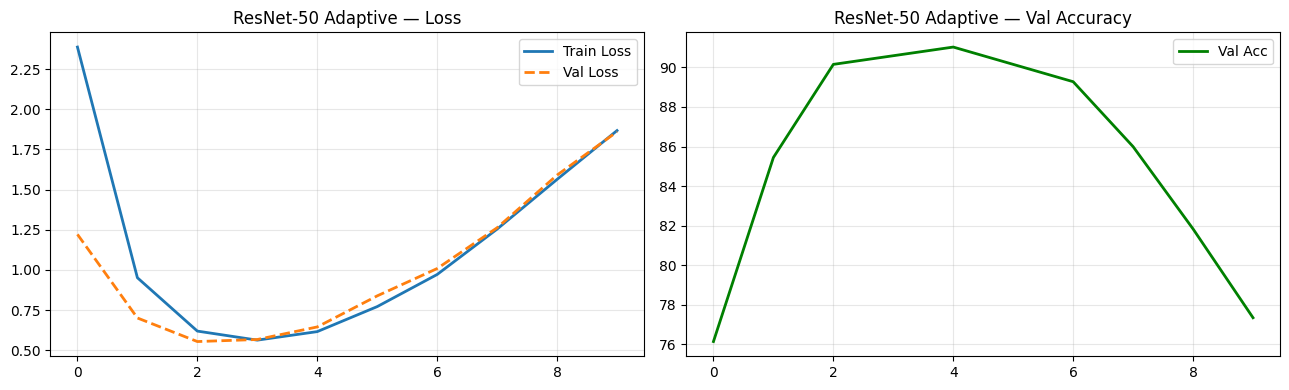

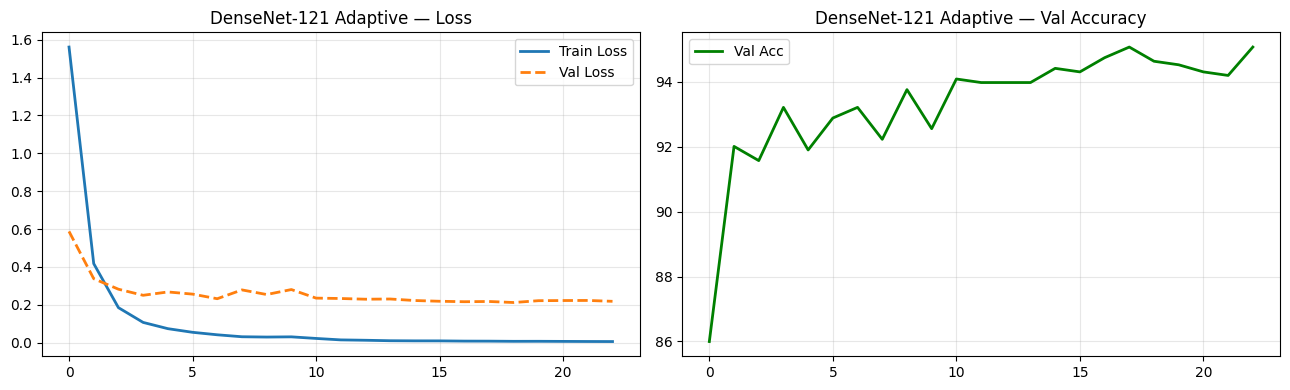

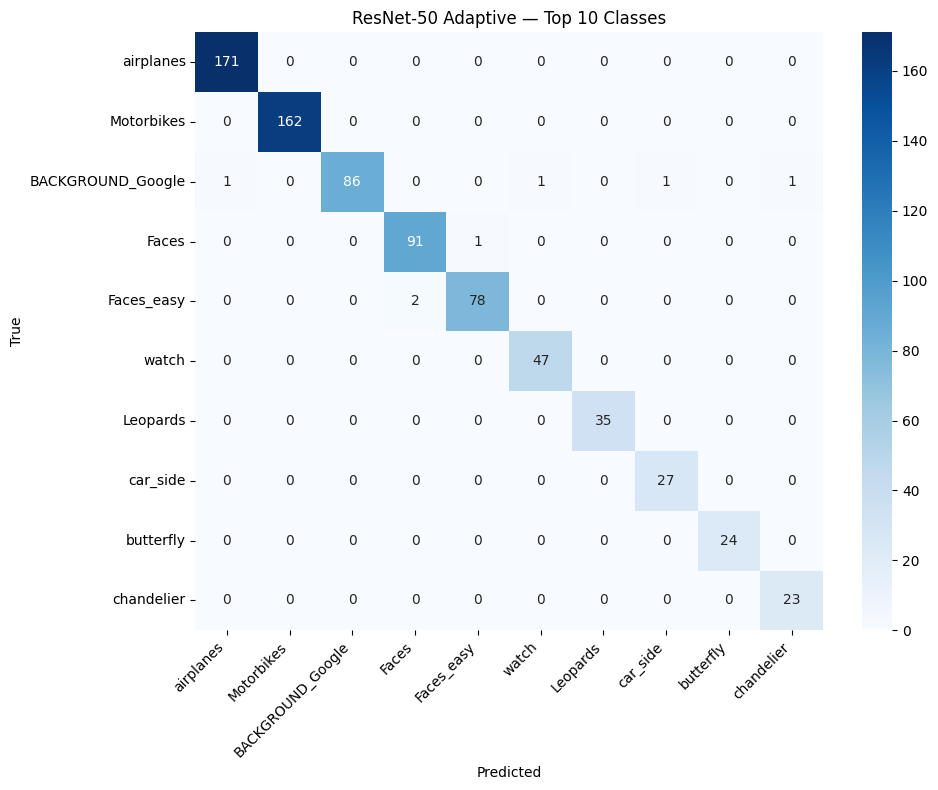

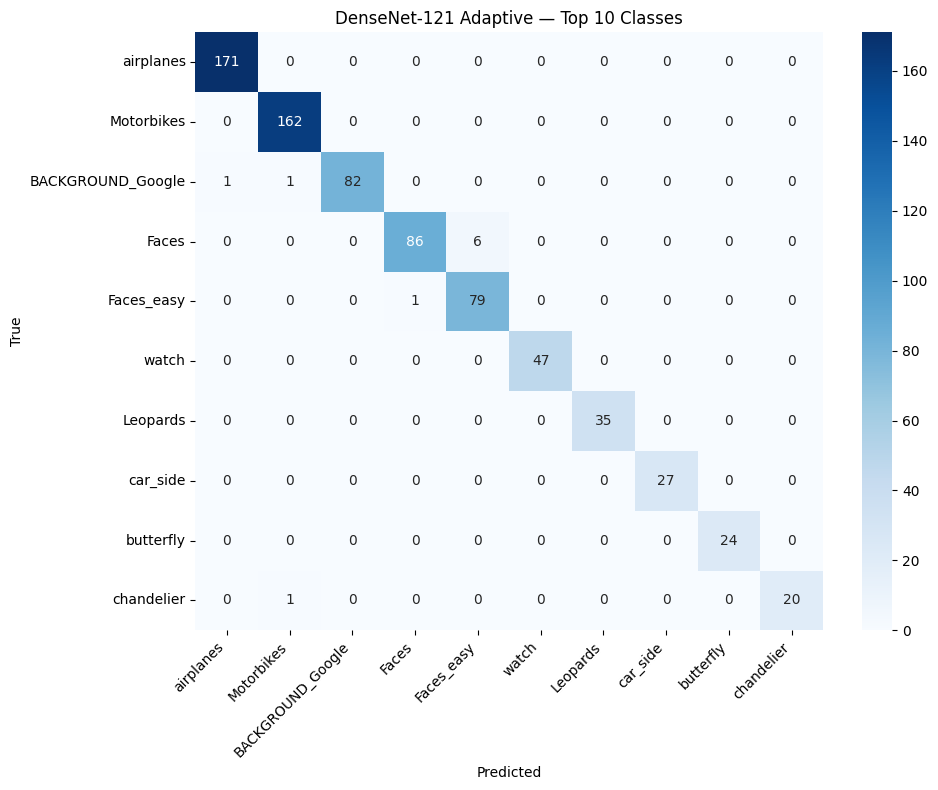

In [60]:
# =====================================================
# STEP 8: Evaluate on Test Set + Plots
# =====================================================

print("\n" + "=" * 60)
print("TEST SET EVALUATION — Adaptive Finetuning")
print("=" * 60)

classes = dataset.classes   # 102 class names from ImageFolder

acc_res, f1_res, cm_res, _, _ = evaluate_model(model_res_adapt, test_loader, device, classes)
acc_den, f1_den, cm_den, _, _ = evaluate_model(model_den_adapt, test_loader, device, classes)

print(f"\nResNet-50    | Test Acc: {acc_res:.2f}% | Macro F1: {f1_res:.4f} | "
      f"Trainable: {res_train_p:,} | Time: {time_res_adapt:.1f}s")
print(f"DenseNet-121 | Test Acc: {acc_den:.2f}% | Macro F1: {f1_den:.4f} | "
      f"Trainable: {den_train_p:,} | Time: {time_den_adapt:.1f}s")

# Loss + accuracy curves
plot_curves(hist_res_adapt, "ResNet-50 Adaptive")
plot_curves(hist_den_adapt, "DenseNet-121 Adaptive")

# Top-10 confusion matrices
plot_top10_confusion(cm_res, classes, "ResNet-50 Adaptive — Top 10 Classes")
plot_top10_confusion(cm_den, classes, "DenseNet-121 Adaptive — Top 10 Classes")

In [ ]:
history = {
    "train_loss": [],
    "val_loss": [],
    "val_acc": []
}

In [63]:
import matplotlib.pyplot as plt

# 🔹 Compute train accuracy from loss loop (if not already stored)
def add_train_accuracy(history, model, train_loader, device):
    model.eval()
    train_acc_list = []

    with torch.no_grad():
        for epoch_idx in range(len(history["train_loss"])):
            correct, total = 0, 0

            for imgs, labels in train_loader:
                imgs, labels = imgs.to(device), labels.to(device)
                outputs = model(imgs)

                preds = outputs.argmax(1)
                correct += (preds == labels).sum().item()
                total += labels.size(0)

            acc = 100 * correct / total
            train_acc_list.append(acc)

    history["train_acc"] = train_acc_list
    return history


# 🔹 Plot function
def plot_acc(history, title="Accuracy Curve"):
    plt.figure(figsize=(6,4))

    plt.plot(history["train_acc"], label="Train Accuracy")
    plt.plot(history["val_acc"], label="Validation Accuracy")

    plt.xlabel("Epoch")
    plt.ylabel("Accuracy (%)")
    plt.title(title)
    plt.legend()
    plt.grid()

    plt.show()

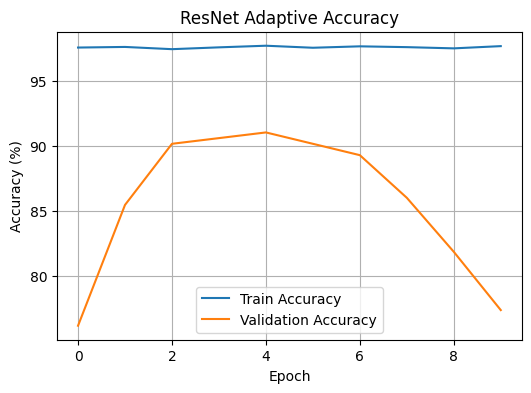

In [64]:
# Add train accuracy
hist_res_adapt = add_train_accuracy(hist_res_adapt, model_res_adapt, train_loader, device)

# Plot
plot_acc(hist_res_adapt, "ResNet Adaptive Accuracy")

In [61]:
# =====================================================
# STEP 9: Comparative Summary Table
# Covers: params, time, accuracy — all rubric points
# =====================================================

print("\n" + "=" * 65)
print("COMPARATIVE ANALYSIS — Adaptive Finetuning")
print("=" * 65)
print(f"{'Metric':<32} {'ResNet-50':>15} {'DenseNet-121':>15}")
print("-" * 65)
print(f"{'Importance Block':<32} {'layer4':>15} {'denseblock4':>15}")
print(f"{'Optimizer':<32} {'Adam':>15} {'Adam':>15}")
print(f"{'Learning Rate':<32} {'1e-4':>15} {'1e-3':>15}")
print(f"{'Scheduler':<32} {'StepLR':>15} {'StepLR':>15}")
print(f"{'Total Params':<32} {res_total_p:>15,} {den_total_p:>15,}")
print(f"{'Trainable Params':<32} {res_train_p:>15,} {den_train_p:>15,}")
print(f"{'Trainable %':<32} {100*res_train_p/res_total_p:>14.2f}% {100*den_train_p/den_total_p:>14.2f}%")
print(f"{'Best Val Acc (%)':<32} {best_res_adapt:>15.2f} {best_den_adapt:>15.2f}")
print(f"{'Test Acc (%)':<32} {acc_res:>15.2f} {acc_den:>15.2f}")
print(f"{'Macro F1':<32} {f1_res:>15.4f} {f1_den:>15.4f}")
print(f"{'Training Time (s)':<32} {time_res_adapt:>15.1f} {time_den_adapt:>15.1f}")


COMPARATIVE ANALYSIS — Adaptive Finetuning
Metric                                 ResNet-50    DenseNet-121
-----------------------------------------------------------------
Importance Block                          layer4     denseblock4
Optimizer                                   Adam            Adam
Learning Rate                               1e-4            1e-3
Scheduler                                 StepLR          StepLR
Total Params                          23,717,030       7,058,406
Trainable Params                      15,151,206       1,865,830
Trainable %                               63.88%          26.43%
Best Val Acc (%)                           91.03           95.08
Test Acc (%)                               91.20           92.40
Macro F1                                  0.8454          0.8864
Training Time (s)                          115.1           266.2
